<a href="https://colab.research.google.com/github/catafiorini/Trabajo-Practico-ALC--2C-2026/blob/main/grupo_alfajorverde_TP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Trabajo Práctico - Álgebra Lineal Computacional
# - Calibración y Pose de la cámara -

## GRUPO: ALFAJOR VERDE

# Integrantes
* Chicolino deLuca Juan Pablo
* D'Angelo Genaro
* Fiorini Catalina
* Flores Garcia Emanuel

In [2]:
# Solo para Colab: traemos el repo con alc.py y los datos
import os
repo = '/content/Trabajo-Practico-ALC--2C-2026'
if os.path.exists(repo):
    !git -C {repo} pull
else:
    !git clone https://github.com/catafiorini/Trabajo-Practico-ALC--2C-2026.git

Cloning into 'Trabajo-Practico-ALC--2C-2026'...
remote: Enumerating objects: 120, done.
remote: Counting objects: 100% (120/120), done.
remote: Compressing objects: 100% (117/117), done.
remote: Total 120 (delta 17), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (120/120), 40.10 MiB | 21.50 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [3]:
import sys
sys.path.insert(0, '/content/Trabajo-Practico-ALC--2C-2026')

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import alc
from alc import *
np.set_printoptions(precision=4, suppress=True) #para printear las matrices mas esteticas

### Ejercicio 1 - DLT ecuaciones formales
a) Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

**Rango de Q**

Buscamos un m ≠ 0 tal que Q·m = 0, es decir, m ∈ Nu(Q). Como Q tiene 12 columnas, por el teorema de la dimensión:

    dim Nu(Q) = 12 − rg(Q)

Para que la solución sea única a menos de un factor de escala, todas las soluciones tienen que ser múltiplos de una sola, o sea, el núcleo tiene que ser una recta: dim Nu(Q) = 1. Entonces:

    rg(Q) = 11

* Si rg(Q) = 12, el núcleo es {0} y solo existe la solución trivial m = 0.
* Si rg(Q) < 11, el núcleo tiene dimensión mayor a 1, hay infinitas direcciones posibles y M no queda determinada.

**Cantidad mínima de puntos**

M tiene 12 coeficientes, pero como está definida a menos de un factor de escala tiene 11 grados de libertad. Cada correspondencia (U, V, W) ↔ (u, v) aporta 2 ecuaciones, es decir, 2 filas de Q. Para alcanzar rango 11 necesitamos:

    2n ≥ 11  →  n ≥ 5,5  →  n ≥ 6

Se necesitan **como mínimo 6 puntos**.

**Condición que deben cumplir**

Los puntos tienen que estar en posición general:

* **No pueden ser todos coplanares.** Si todos están en un mismo plano, Q pierde rango y la solución deja de ser única. Por eso el caso de puntos coplanares se resuelve con una homografía (Ejercicio 3).
* Tampoco pueden estar todos alineados.

En la mira de `calib/3d` hay 12 puntos repartidos en distintos planos, así que se cumple la condición.

b )Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 8.

**Planteo**

Queremos resolver:

    min  mᵀ QᵀQ m    sujeto a  ‖m‖ = 1

La restricción ‖m‖ = 1 evita la solución trivial m = 0 y fija la escala de M.

**Multiplicadores de Lagrange**

Como ‖m‖ = 1 es lo mismo que mᵀm = 1, armamos el lagrangiano:

    L(m, λ) = mᵀ QᵀQ m − λ (mᵀm − 1)

Derivando respecto de m e igualando a cero (QᵀQ es simétrica):

    2 QᵀQ m − 2 λ m = 0   →   QᵀQ m = λ m

Es decir, los candidatos a solución son los **autovectores de QᵀQ**.

**Cuál de los autovectores**

Si m es un autovector unitario con autovalor λ, el valor de la función es:

    mᵀ QᵀQ m = λ mᵀm = λ

Entonces, para minimizar, nos quedamos con el autovalor más chico. Como QᵀQ es simétrica y semidefinida positiva, todos sus autovalores son reales y mayores o iguales a 0.

**Conclusión:** el vector m que minimiza es el **autovector unitario de QᵀQ asociado a su menor autovalor**. Es equivalente al vector singular a derecha de Q asociado al menor valor singular. Con datos exactos ese autovalor es 0 y m está en el núcleo de Q.

**Cómo lo calculamos**

En `resolverDLT3D` usamos el método de la potencia inversa: el menor autovalor de QᵀQ es el mayor autovalor de (QᵀQ)⁻¹, así que iterar

    x_(k+1) = (QᵀQ)⁻¹ x_k / ‖(QᵀQ)⁻¹ x_k‖

converge a m. Para no calcular la inversa, factorizamos QᵀQ = LU una sola vez y, en cada paso, resolvemos dos sistemas triangulares (L z = x_k y U y = z). Por último, reacomodamos m como las 3 filas de M.

### Ejercicio 2 - Calibración con puntos 3D
:a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$

In [4]:
# ---- Ejercicio 2 a): calibración con la mira 3D

# Carpeta con los datos del template dentro del repo
CARPETA_DATOS = '/content/Trabajo-Practico-ALC--2C-2026/template-alumnos-20261020'
carpeta_3d = os.path.join(CARPETA_DATOS, 'calib', '3d')

# Coordenadas reales (U, V, W) de los 12 puntos de la mira
puntos_mundo = np.loadtxt(os.path.join(carpeta_3d, 'p_W_corners.txt'), delimiter=',')

# Posiciones en la imagen: cada fila es un cuadro del video con (u1, v1, ..., u12, v12)
esquinas_detectadas = np.loadtxt(os.path.join(carpeta_3d, 'detected_corners.txt'))

# Tomamos el primer cuadro (img_0001) y separamos u (columnas pares) y v (columnas impares)
u = esquinas_detectadas[0, 0::2]
v = esquinas_detectadas[0, 1::2]
puntos_imagen = np.vstack([u, v]).T     # matriz de 12 x 2

# Armamos Q y resolvemos el DLT para obtener M
Q = alc.obtenerQ3d(puntos_imagen, puntos_mundo)
M = alc.resolverDLT3D(Q)

# Descomponemos M en K, R y t
R, t, K = alc.devolverMatricesCalibracion3d(M)

print('K =\n', K)
print('\nR =\n', R)
print('\nt =', t)

K =
 [[425.8599  -0.0156 354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]

R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]

t = [-18.1679 -14.5033  40.5913]


**Resultados del inciso a)**

* **K:** las distancias focales en píxeles son αu ≈ 425,86 y αv ≈ 424,57. Como son casi iguales, los píxeles son prácticamente cuadrados. El punto principal (u₀, v₀) ≈ (354,4; 256,9) queda cerca del centro de la imagen. El sesgo K12 ≈ −0,016 es despreciable frente a αu, lo que confirma que se puede suponer K12 = 0.
* **R:** es la rotación entre el sistema de la mira y el de la cámara.
* **t:** su tercera componente t₃ ≈ 40,6 es positiva, o sea que la mira queda delante de la cámara.

In [5]:
# ---- Ejercicio 2 b) y c): calibración con restricciones sobre K
# Usamos la misma M del inciso a) y solo cambiamos la descomposición

# b) Imponemos alfa_u = alfa_v
R_b, t_b, K_b = alc.devolverMatricesCalibracion3d(M, alfasIguales=True)

print('b) alfa_u = alfa_v')
print('K =\n', K_b)
print('R =\n', R_b)
print('t =', t_b)

# c) Imponemos K12 = 0 (sin sesgo)
R_c, t_c, K_c = alc.devolverMatricesCalibracion3d(M, sinSesgo=True)

print('\nc) K12 = 0')
print('K =\n', K_c)
print('R =\n', R_c)
print('t =', t_c)

b) alfa_u = alfa_v
K =
 [[425.2126  -0.0156 354.4185]
 [  0.     425.2126 256.8534]
 [  0.       0.       1.    ]]
R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t = [-18.1956 -14.4812  40.5913]

c) K12 = 0
K =
 [[425.8599   0.     354.4185]
 [  0.     424.5653 256.8534]
 [  0.       0.       1.    ]]
R =
 [[ 0.6182  0.1292 -0.7753]
 [-0.3551  0.9259 -0.1288]
 [ 0.7012  0.3549  0.6183]]
t = [-18.1674 -14.5033  40.5913]


**Resultados de los incisos b) y c)**

* **b) αu = αv:** ambas distancias focales quedan en el promedio, ≈ 425,21 px. Como en el inciso a) ya diferían menos de un 0,5 %, el cambio es muy chico.
* **c) K12 = 0:** el resto de K queda igual que en a). El sesgo original (≈ −0,016) era despreciable, así que imponerlo en 0 casi no cambia nada.
* **R** es prácticamente la misma en los tres casos (coincide en los 4 decimales mostrados), porque las modificaciones sobre K son muy chicas.
* **t** cambia apenas en sus dos primeras componentes, y t₃ ≈ 40,59 se mantiene. La traslación se recalcula con la K nueva, y K afecta sobre todo a las coordenadas u y v.

En conclusión, las hipótesis habituales de píxeles cuadrados (αu = αv) y sin sesgo (K12 = 0) son razonables para esta cámara.

### Ejercicio 3 - Calibración con puntos coplanares
Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.

a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

**Rango de Q**

Con el mismo razonamiento que en el Ejercicio 1: h tiene 9 componentes, pero como H está definida a menos de un factor de escala, tiene 8 grados de libertad. Para que la solución sea única a menos de escala, el núcleo de Q tiene que ser una recta:

    dim Nu(Q) = 9 − rg(Q) = 1   →   rg(Q) = 8

Cada punto aporta 2 ecuaciones, así que se necesitan **al menos 4 puntos**, sin que haya 3 alineados. El tablero tiene 11 × 7 = 77 esquinas internas, mucho más que el mínimo.

**Sistema de coordenadas del tablero**

Tomamos el origen en una esquina interna, los ejes U y V a lo largo de los lados y W = 0. Así, las esquinas internas tienen coordenadas (30·i, 30·j) mm, con i = 0, …, 10 y j = 0, …, 6.

In [6]:
# ---- Ejercicio 3: coordenadas del tablero (en mm)
# Esquinas internas: 11 x 7, cuadrados de 30 mm, W = 0
# Recorremos fila por fila: primero las 11 esquinas con j = 0, después j = 1, etc.

tam_cuadrado = 30.0
puntos_tablero = np.zeros((77, 2))

k = 0
for j in range(7):          # filas del tablero (eje V)
    for i in range(11):     # columnas del tablero (eje U)
        puntos_tablero[k, 0] = tam_cuadrado * i     # U
        puntos_tablero[k, 1] = tam_cuadrado * j     # V
        k = k + 1

print(puntos_tablero.shape)
print(puntos_tablero[:13])

(77, 2)
[[  0.   0.]
 [ 30.   0.]
 [ 60.   0.]
 [ 90.   0.]
 [120.   0.]
 [150.   0.]
 [180.   0.]
 [210.   0.]
 [240.   0.]
 [270.   0.]
 [300.   0.]
 [  0.  30.]
 [ 30.  30.]]


**Detección de las esquinas del tablero**

En la carpeta `calib/coplanar` solo están las imágenes, sin las posiciones (u, v) de las esquinas. Para obtenerlas usamos `cv2.findChessboardCorners`, únicamente para detectar las esquinas en la imagen. La calibración (homografías, K y poses) está implementada con nuestras funciones del módulo `alc`.

In [7]:
# ---- Ejercicio 3: detección de las esquinas en cada imagen
carpeta_coplanar = os.path.join(CARPETA_DATOS, 'calib', 'coplanar')
archivos = os.listdir(carpeta_coplanar)

vistas = []             # número de cada imagen que se pudo usar
puntos_imagen_2d = []   # esquinas (u, v) detectadas en cada imagen, 77 x 2

for numero in range(1, 21):
    nombre = 'Im_R_' + str(numero) + '.png'

    # Si la imagen no está en la carpeta, la salteamos
    if nombre not in archivos:
        continue

    # Leemos la imagen en escala de grises y buscamos las 11 x 7 esquinas internas
    imagen = cv2.imread(os.path.join(carpeta_coplanar, nombre), cv2.IMREAD_GRAYSCALE)
    encontrado, esquinas = cv2.findChessboardCorners(imagen, (11, 7))

    if encontrado:
        vistas.append(numero)
        puntos_imagen_2d.append(esquinas.reshape(77, 2))
    else:
        print(nombre, ': no se detectó el tablero')

print('Imágenes usadas:', vistas)

Imágenes usadas: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [8]:
# ---- Ejercicio 3: homografía de cada vista
lista_H = []

for k in range(len(vistas)):
    # Armamos Q con las esquinas de la imagen y las coordenadas del tablero
    Q_2d = alc.obtenerQ2d(puntos_imagen_2d[k], puntos_tablero)

    # Resolvemos Q h = 0 y reacomodamos h como la matriz H de 3 x 3
    H = alc.resolverDLT2D(Q_2d)
    lista_H.append(H)

print('Cantidad de homografías:', len(lista_H))
print('Tamaño de Q:', Q_2d.shape)
print('H de la primera imagen =\n', lista_H[0])

Cantidad de homografías: 10
Tamaño de Q: (154, 9)
H de la primera imagen =
 [[ 0.0036 -0.0001  0.963 ]
 [ 0.0001  0.0035  0.2695]
 [ 0.     -0.      0.0026]]


In [9]:
# ---- Ejercicio 3 a): matriz K
# Cada homografía aporta 2 filas a A (perpendicularidad e igual norma de r1 y r2)
A_zhang = alc.armarA(lista_H)
print('Tamaño de A:', A_zhang.shape)

# Resolvemos A b = 0, armamos B y obtenemos K por Cholesky
K_2d = alc.calcularMatrizK2D(A_zhang)
print('\nK =\n', K_2d)

Tamaño de A: (20, 6)

K =
 [[742.7054  -0.6847 520.4613]
 [  0.     753.9445 299.3382]
 [  0.       0.       1.    ]]


**Resultado del inciso a)**

* Las distancias focales en píxeles son αu ≈ 742,7 y αv ≈ 753,9. Difieren un 1,5 %, así que los píxeles son casi cuadrados.
* El sesgo K12 ≈ −0,68 es despreciable frente a αu.
* El punto principal (u₀, v₀) ≈ (520,5; 299,3) está cerca del centro de la imagen, que mide 1024 × 576 y tiene su centro en (512, 288).

### Ejercicio 4 - Fútbol
a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad
a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

#### Paso 1: Carga de datos

El archivo `world_img_pts.csv` contiene 5 puntos de la esquina con sus coordenadas reales (X, Y, Z) en metros y su posición (u, v) en píxeles en cada una de las 4 vistas.

Como el método de calibración con homografías supone que los puntos están sobre un plano, tomamos solo las coordenadas (X, Y) del piso. Los puntos son los mismos en todas las vistas; lo que cambia es dónde aparecen en cada imagen.

In [10]:
carpeta_salguero = os.path.join(CARPETA_DATOS, 'salguero')
datos = pd.read_csv(os.path.join(carpeta_salguero, 'world_img_pts.csv'), sep=';')

# Coordenadas de los puntos sobre el plano del piso (iguales para todas las vistas)
objPts = datos[['X', 'Y']].to_numpy(dtype=np.float64)     # forma (5, 2)

# Coordenadas en píxeles de los puntos, una matriz por vista
n_vistas = 4
imgPts_vistas = []
for k in range(n_vistas):
    imgPts_k = datos[['u_' + str(k), 'v_' + str(k)]].to_numpy(dtype=np.float64)   # forma (5, 2)
    imgPts_vistas.append(imgPts_k)

datos

,pts,X,Y,Z,u_0,v_0,u_1,v_1,u_2,v_2,u_3,v_3
0,6,-4.0,3,0.0,281,474,255,490,469,581,446,563
1,36,4.0,0,0.0,889,521,1071,577,1147,653,1118,621
2,40,6.5,3,0.1,1139,493,1403,550,1425,625,1396,590
3,41,-5.0,14,0.1,418,385,437,377,627,485,600,466
4,42,-5.0,76,0.1,833,262,997,227,1094,357,1064,331


#### Paso 2: Estimación de la homografía de cada vista

Como los puntos están sobre el piso (Z = 0), en cada vista la relación entre el plano de la calle y la imagen es una homografía:

(u, v, 1) ~ H_k · (X, Y, 1)

H_k tiene 9 coeficientes pero está definida salvo un factor de escala, así que tiene 8 grados de libertad. Cada punto aporta 2 ecuaciones (una para u y otra para v), por lo que se necesitan al menos 4 puntos. Contamos con 5.

Para cada vista armamos el sistema Q h = 0 con `obtenerQ2d` y lo resolvemos con `resolverDLT2D`, que busca el h de norma 1 que minimiza ‖Q h‖. Al final normalizamos cada H para que H[2,2] = 1.

In [11]:
Hlst = []
for k in range(n_vistas):
    Q_k = alc.obtenerQ2d(imgPts_vistas[k], objPts)   # sistema de ecuaciones de la vista k
    H_k = alc.resolverDLT2D(Q_k)                     # homografía de la vista k
    H_k = H_k / H_k[2, 2]                            # fijamos la escala
    Hlst.append(H_k)

for k in range(n_vistas):
    print('H de la vista', k)
    print(H_k if False else Hlst[k])
    print()

H de la vista 0
[[ 80.1035  35.3547 530.1804]
 [ -2.3593   4.8374 504.6762]
 [ -0.0115   0.0306   1.    ]]

H de la vista 1
[[109.4438  42.8987 592.6858]
 [  2.4512   2.9135 541.0924]
 [ -0.0103   0.0298   1.    ]]

H de la vista 2
[[ 88.3236  45.2339 746.5928]
 [ -0.5948   7.7995 623.6593]
 [ -0.0108   0.0312   1.    ]]

H de la vista 3
[[ 86.8531  43.5382 720.4562]
 [ -2.6482   6.6278 599.5238]
 [ -0.0118   0.0305   1.    ]]



In [12]:
    print(Hlst[k])

[[ 86.8531  43.5382 720.4562]
 [ -2.6482   6.6278 599.5238]
 [ -0.0118   0.0305   1.    ]]


#### Paso 3: Restricciones sobre K a partir de cada homografía

Cada homografía cumple H ~ K · [r1  r2  t]. Si c1 y c2 son sus dos primeras columnas, salvo un factor de escala s:

c1 = s · K · r1        c2 = s · K · r2

Como r1 y r2 son columnas de una matriz de rotación, son perpendiculares y tienen la misma norma:

r1ᵀ r2 = 0        r1ᵀ r1 = r2ᵀ r2

Despejando r1 y r2 y reemplazando, las condiciones quedan en función de B = K⁻ᵀ K⁻¹:

c1ᵀ B c2 = 0
c1ᵀ B c1 − c2ᵀ B c2 = 0

De esta forma eliminamos R y t: las incógnitas dependen solo de K.

B es simétrica, así que tiene 6 valores distintos, que agrupamos en b = (B11, B12, B22, B13, B23, B33). Cada expresión ciᵀ B cj es lineal en b y se escribe como vijᵀ b. Entonces cada vista aporta dos filas al sistema A b = 0:

v12ᵀ b = 0        (v11 − v22)ᵀ b = 0

Con 4 vistas, A es de 8 × 6. Como b está definido salvo escala, tiene 5 incógnitas, así que se necesitan al menos 3 vistas.

In [13]:
A = alc.armarA(Hlst)
print('Forma de A:', A.shape)     # 2 filas por vista, 6 columnas
print(A)

Forma de A: (8, 6)
[[ 2832.036    304.0797   -11.4131     2.0434    -0.1278    -0.0004]
 [ 5166.6227  -720.0336   -17.834     -4.0045    -0.2416    -0.0008]
 [ 4695.0017   424.0153     7.1414     2.8213     0.0431    -0.0003]
 [10137.6413   286.5576    -2.4803    -4.8036    -0.224     -0.0008]
 [ 3995.2252   661.9746    -4.6394     2.2617    -0.103     -0.0003]
 [ 5754.9548  -810.6795   -60.4785    -4.7303    -0.4731    -0.0009]
 [ 3781.4262   460.3509   -17.5516     2.1394    -0.1589    -0.0004]
 [ 5647.8788 -1037.1291   -36.9153    -4.703     -0.3424    -0.0008]]


#### Paso 4: Cálculo de K

Resolvemos A b = 0 buscando el b de norma 1 que minimiza ‖A b‖. Ese b es el autovector de AᵀA asociado al menor autovalor, y lo obtenemos con `resolverHomogeneo` (método de la potencia inversa).

Con b armamos la matriz simétrica B. Como b se obtiene salvo un signo, si B no resulta definida positiva la multiplicamos por −1.

Como B = K⁻ᵀ K⁻¹, aplicamos la factorización de Cholesky B = L Lᵀ. Así L = K⁻ᵀ, y por lo tanto K = (Lᵀ)⁻¹. Por último normalizamos para que K[2,2] = 1.

Todo esto lo hace la función `calcularMatrizK2D`.

In [14]:
K_salguero = alc.calcularMatrizK2D(A)
print(K_salguero)

[[2803.1419 1278.3942  334.842 ]
 [   0.      230.9822  213.2788]
 [   0.        0.        1.    ]]


**Análisis del resultado**

La matriz K obtenida no tiene sentido físico para una imagen de 1600 × 1200 píxeles:
- αu ≈ 2803 y αv ≈ 231 deberían ser similares (píxeles aproximadamente cuadrados).
- El sesgo K12 ≈ 1278 debería ser cercano a 0.
- El centro (u0, v0) ≈ (335, 213) debería estar cerca del centro de la imagen, (800, 600).

Creemos que esto se debe a que el método supone que todos los puntos están en el plano Z = 0, pero 3 de los 5 puntos se encuentran sobre el cordón, a Z = 0,1 m. Con tan pocos puntos, esa diferencia afecta mucho la estimación. Además, las 4 vistas son muy parecidas entre sí, por lo que el sistema A b = 0 está mal condicionado.

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

### Pose de la cámara y reproyección

#### Paso 1: Carga de las correspondencias de la vista inicial

El archivo `gs_10_09_point_correspondences_v5.txt` contiene 51 puntos organizados en 6 filas, con una columna por punto:
- fila 0: índice del punto
- filas 1, 2 y 3: coordenadas X, Y, Z en metros
- filas 4 y 5: coordenadas u, v en píxeles en la imagen `img_10_18_47_351.jpg`

Todos estos puntos tienen Z = 0: están sobre el piso (senda peatonal, cordón y líneas de la calle).

In [15]:
gs = np.loadtxt(os.path.join(carpeta_salguero, 'gs_10_09_point_correspondences_v5.txt'))
print('Forma del archivo:', gs.shape)

objPts_gs = gs[1:3, :].T
mundo_gs  = gs[1:4, :].T
imgPts_gs = gs[4:6, :].T

print('Valores distintos de Z:', np.unique(gs[3, :]))

Forma del archivo: (6, 51)
Valores distintos de Z: [0.]


#### Paso 2: Homografía de la vista inicial

Como los 51 puntos están en el plano Z = 0, la relación entre el piso y la imagen es una homografía:

(u, v, 1) ~ H · (X, Y, 1)

La estimamos igual que en el 5a: armamos el sistema Q h = 0 con `obtenerQ2d` y lo resolvemos con `resolverDLT2D`. Con 51 puntos tenemos 102 ecuaciones para 8 incógnitas, así que la homografía queda mucho mejor determinada que con los 5 puntos del 5a.

In [16]:
Q_gs = alc.obtenerQ2d(imgPts_gs, objPts_gs)
H_gs = alc.resolverDLT2D(Q_gs)
H_gs = H_gs / H_gs[2, 2]       # fijamos la escala para que H[2,2] = 1

print(H_gs)

[[ 80.3208  46.0588 513.7652]
 [ -1.0476   7.6833 511.148 ]
 [ -0.0067   0.042    1.    ]]


#### Paso 3: Estimación de K con un modelo simplificado

Estimamos K a partir de esta misma vista, cuyos 51 puntos son realmente coplanares.

Una sola vista aporta solo 2 ecuaciones, que no alcanzan para los 5 parámetros de una K general. Por eso reducimos las incógnitas con tres hipótesis habituales:
- sesgo nulo (K12 = 0)
- píxeles cuadrados (αu = αv = f)
- centro de la imagen en el medio: (cx, cy) = (800, 600), porque la imagen es de 1600 × 1200

Con estas hipótesis la única incógnita es f.

1. Trasladamos el origen de los píxeles al centro de la imagen con la matriz
   T = [[1, 0, −cx], [0, 1, −cy], [0, 0, 1]].
   La homografía pasa a ser H' = T · H, y la matriz de intrínsecos en estas coordenadas es K' = diag(f, f, 1).

2. Entonces B' = K'⁻ᵀ K'⁻¹ = diag(1/f², 1/f², 1). Es decir:
   B12 = B13 = B23 = 0  y  B11 = B22.

3. Reemplazando en A b = 0 (armada con H' como en el 5a), cada fila queda:
   (A[:,0] + A[:,2]) · B11 + A[:,5] · B33 = 0
   Es un sistema homogéneo con 2 incógnitas, x = (B11, B33), y 2 ecuaciones.

4. Lo resolvemos con `resolverHomogeneo`. Como B11 / B33 = 1/f², obtenemos f = raíz(B33 / B11).

In [17]:
# Centro de la imagen (1600 x 1200)
cx, cy = 800, 600

# Matriz que traslada el origen de los píxeles al centro de la imagen
T = np.array([[1, 0, -cx],
              [0, 1, -cy],
              [0, 0, 1]], dtype=np.float64)

H_gs_centrada = alc.multiplicar(T, H_gs)

# Las dos ecuaciones de esta vista (igual que en el 5a)
A_gs = alc.armarA([H_gs_centrada])

# Sistema reducido: incógnitas (B11, B33)
A_gs_red = np.zeros((A_gs.shape[0], 2))
A_gs_red[:, 0] = A_gs[:, 0] + A_gs[:, 2]    # B11 y B22 son iguales: se suman sus columnas
A_gs_red[:, 1] = A_gs[:, 5]                 # columna de B33
A_gs_red = A_gs_red / np.max(np.abs(A_gs_red))   # escalado para estabilidad numérica

x_gs = alc.resolverHomogeneo(A_gs_red)
f_gs = np.sqrt(x_gs[1] / x_gs[0])

K_gs = np.array([[f_gs, 0, cx],
                 [0, f_gs, cy],
                 [0, 0, 1]])
print(K_gs)

[[2001.1461    0.      800.    ]
 [   0.     2001.1461  600.    ]
 [   0.        0.        1.    ]]


#### Paso 4: Cálculo de la pose

Con K conocida, de H ~ K · [r1  r2  t] despejamos:

K⁻¹ · H ~ [r1  r2  t]

La función `obtenerPose2D` hace lo siguiente:
1. Multiplica K⁻¹ por cada columna de H. Así obtiene r1, r2 y t, todos multiplicados por un mismo factor de escala.
2. Calcula ese factor imponiendo que r1 tenga norma 1.
3. Elige el signo para que la tercera componente de t sea positiva, es decir, para que la escena quede delante de la cámara.
4. Calcula r3 = r1 × r2 (producto vectorial), el eje perpendicular al piso.
5. Como con datos reales R no queda exactamente ortonormal, ortonormaliza sus columnas con Gram-Schmidt.

In [18]:
R_gs, t_gs = alc.obtenerPose2D(H_gs, K_gs)

print('R =')
print(R_gs)
print('t =', t_gs)

R =
[[ 0.9874  0.1585  0.002 ]
 [ 0.0343 -0.2014 -0.9789]
 [-0.1547  0.9666 -0.2043]]
t = [-3.2982 -1.0238 23.0585]


#### Paso 5: Reproyección de los puntos

Para verificar la calibración y la pose, reproyectamos los 51 puntos: tomamos sus coordenadas reales (X, Y, Z) y les aplicamos el modelo completo de la cámara.

1. Pasamos cada punto a coordenadas de la cámara: R · X + t
2. Aplicamos K: q = K · (R · X + t)
3. Pasamos de coordenadas homogéneas a píxeles dividiendo por la tercera coordenada: (u, v) = (q1 / q3, q2 / q3)

Después comparamos esos píxeles con los marcados en la imagen. El error de cada punto es la distancia en píxeles entre ambos. Si K, R y t son correctos, los puntos reproyectados deberían caer sobre los marcados.

Error RMS: 14.24485872592537 px
Error máximo: 36.30844711015479 px


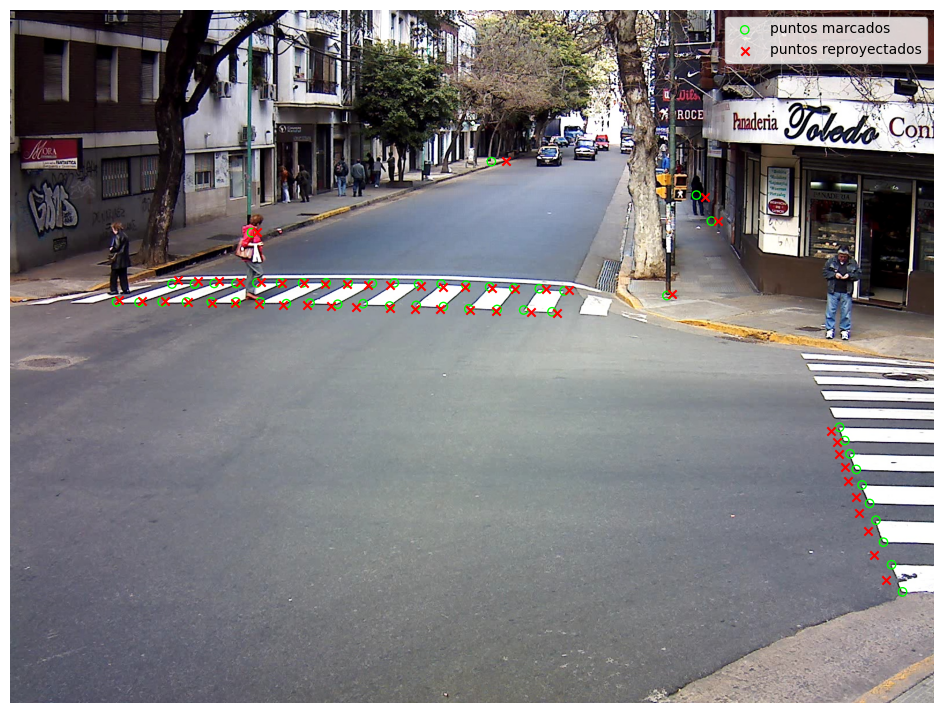

In [19]:
# 1) Coordenadas de cámara: R X + t (una columna por punto)
X_cam = alc.multiplicar(R_gs, mundo_gs.T) + t_gs.reshape(3, 1)

# 2) Aplicamos K
q = alc.multiplicar(K_gs, X_cam)

# 3) De homogéneas a píxeles
reproy_gs = (q[0:2, :] / q[2, :]).T          # forma (51, 2)

# Error de cada punto: distancia entre el reproyectado y el marcado
errores = np.sqrt(np.sum((reproy_gs - imgPts_gs) ** 2, axis=1))
print('Error RMS:', np.sqrt(np.mean(errores ** 2)), 'px')
print('Error máximo:', np.max(errores), 'px')

# Gráfico sobre la imagen inicial
img_inicial = plt.imread(os.path.join(carpeta_salguero, 'img_10_18_47_351.jpg'))
plt.figure(figsize=(12, 9))
plt.imshow(img_inicial)
plt.scatter(imgPts_gs[:, 0], imgPts_gs[:, 1], marker='o', facecolors='none',
            edgecolors='lime', label='puntos marcados')
plt.scatter(reproy_gs[:, 0], reproy_gs[:, 1], marker='x', color='red',
            label='puntos reproyectados')
plt.legend()
plt.axis('off')
plt.show()

**Conclusión**

El error RMS de reproyección es de aproximadamente 14 píxeles en una imagen de 1600 × 1200, y los puntos reproyectados coinciden visualmente con los marcados. Consideramos que la calibración y la pose obtenidas son adecuadas. El error remanente se puede atribuir a la imprecisión del marcado manual de los puntos y a las hipótesis del modelo simplificado de K.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Cálculo de velocidades

#### Paso 1: Lectura de las capturas y sus tiempos

La secuencia tiene 46 capturas del video, tomadas con la misma cámara y el mismo encuadre que la imagen del 5b. Por eso la calibración y la pose obtenidas en el 5b son válidas para todas.

El nombre de cada captura indica el instante en que fue registrada, con el formato img_HH_MM_SS_mmm (horas, minutos, segundos y milisegundos).

Pasamos cada nombre a segundos y tomamos como t = 0 la primera captura.

In [20]:
carpeta_secuencia = os.path.join(carpeta_salguero, 'gs_dataset-20261031T142607Z-1-001', 'gs_dataset')

# Nombres de las capturas, ordenados cronológicamente
nombres = sorted([n for n in os.listdir(carpeta_secuencia) if n.endswith('.jpg')])
print('Cantidad de capturas:', len(nombres))

def tiempo_desde_nombre(nombre):
    # 'img_10_18_47_351.jpg' -> ['img', '10', '18', '47', '351']
    partes = nombre.replace('.jpg', '').split('_')
    horas, minutos, segundos, milis = int(partes[1]), int(partes[2]), int(partes[3]), int(partes[4])
    return horas * 3600 + minutos * 60 + segundos + milis / 1000

tiempos = np.array([tiempo_desde_nombre(n) for n in nombres])
tiempos = tiempos - tiempos[0]          # t = 0 en la primera captura

for n, t in zip(nombres, tiempos):
    print(n, '->', round(t, 3), 's')

Cantidad de capturas: 46
img_10_18_47_351.jpg -> 0.0 s
img_10_18_47_461.jpg -> 0.11 s
img_10_18_47_554.jpg -> 0.203 s
img_10_18_47_679.jpg -> 0.328 s
img_10_18_47_835.jpg -> 0.484 s
img_10_18_47_882.jpg -> 0.531 s
img_10_18_48_022.jpg -> 0.671 s
img_10_18_48_163.jpg -> 0.812 s
img_10_18_48_209.jpg -> 0.858 s
img_10_18_48_350.jpg -> 0.999 s
img_10_18_48_475.jpg -> 1.124 s
img_10_18_48_724.jpg -> 1.373 s
img_10_18_48_818.jpg -> 1.467 s
img_10_18_49_005.jpg -> 1.654 s
img_10_18_49_099.jpg -> 1.748 s
img_10_18_49_286.jpg -> 1.935 s
img_10_18_49_317.jpg -> 1.966 s
img_10_18_49_457.jpg -> 2.106 s
img_10_18_49_582.jpg -> 2.231 s
img_10_18_49_660.jpg -> 2.309 s
img_10_18_49_785.jpg -> 2.434 s
img_10_18_49_879.jpg -> 2.528 s
img_10_18_49_988.jpg -> 2.637 s
img_10_18_50_128.jpg -> 2.777 s
img_10_18_50_206.jpg -> 2.855 s
img_10_18_50_300.jpg -> 2.949 s
img_10_18_50_471.jpg -> 3.12 s
img_10_18_50_534.jpg -> 3.183 s
img_10_18_50_674.jpg -> 3.323 s
img_10_18_50_783.jpg -> 3.432 s
img_10_18_50_893.jp

#### Paso 2: Homografía del piso y conversión de píxeles a metros

Los autos y la señora se mueven sobre el piso, es decir, en Z = 0. Para esos puntos, el modelo de la cámara se reduce a una homografía armada con la calibración y la pose del 5b:

H_piso = K · [r1  r2  t]

donde r1 y r2 son las dos primeras columnas de R. H_piso lleva un punto (X, Y) del piso a un píxel (u, v). Para hacer el camino inverso, de píxel a metros, usamos su inversa:

(X, Y, 1) ~ H_piso⁻¹ · (u, v, 1)

Al final dividimos por la tercera coordenada para pasar de coordenadas homogéneas a metros.

In [21]:
# Homografía del piso a partir de K, R y t del 5b
M_pose = np.zeros((3, 3))
M_pose[:, 0] = R_gs[:, 0]     # r1
M_pose[:, 1] = R_gs[:, 1]     # r2
M_pose[:, 2] = t_gs           # t
H_piso = alc.multiplicar(K_gs, M_pose)
H_piso_inv = alc.inversa(H_piso)

def pixel_a_metros(u, v):
    p = alc.multiplicar(H_piso_inv, np.array([u, v, 1.0])).reshape(-1)
    return p[0:2] / p[2]          # (X, Y) en metros

# Prueba con un punto conocido del 5b: el punto 35 está en (5, 3) m y en el píxel (959, 486)
print(pixel_a_metros(959, 486))

[4.9004 2.8351]


#### Paso 3: Marcado de la posición de cada agente

En cada captura elegida marcamos a mano el píxel donde el agente toca el piso:
- señora: punto medio entre los pies
- taxi y camioneta: punto de contacto de la rueda delantera izquierda con el asfalto

El punto tiene que estar sobre el piso (Z = 0) para que la conversión con H_piso sea válida, y tiene que ser el mismo en todas las capturas, para medir el desplazamiento de un mismo punto del agente.

No usamos todas las capturas consecutivas: entre capturas tan cercanas el desplazamiento es de pocos píxeles y el error de marcado manual tendría mucho peso.

In [62]:
def ver_captura(indice, u_centro=None, v_centro=None, mitad=80):
    img = plt.imread(os.path.join(carpeta_secuencia, nombres[indice]))
    plt.figure(figsize=(8,5))
    plt.imshow(img)
    if u_centro is not None:
        # zoom alrededor de (u_centro, v_centro); los ejes siguen en píxeles reales
        plt.xlim(u_centro - mitad, u_centro + mitad)
        plt.ylim(v_centro + mitad, v_centro - mitad)
        plt.grid(True, color='yellow', linewidth=0.5)
    plt.title(f'Captura {indice}: {nombres[indice]}  (t = {tiempos[indice]:.3f} s)')
    plt.show()

# Se sacaron los pixeles de las diferentes capturas.


In [57]:
# Cada marca: (índice de la captura, u, v)
marcas_senora = [
    (0, 422, 498),
    (5, 500, 494),
    (10, 556, 495),
    (15, 650, 495),
    (20, 715, 491),
    (25, 782, 490),
    (30, 842, 490),
    (35, 890, 488),
    (40, 951, 487),
    (45, 990, 487),
]

marcas_taxi = [
    (24, 820, 331),
    (28, 778, 355),
    (32, 735, 379),
    (36, 663, 418),
    (40, 562, 474),
    (44, 428, 540),
]

marcas_camioneta = [
    (24, 986, 304),
    (28, 974, 316),
    (32, 960, 331),
    (36, 935, 362),
    (40, 905, 398),
    (44, 868, 438),
]

#### Paso 4: Posiciones reales de cada agente

Convertimos cada marca (u, v) a coordenadas (X, Y) en metros sobre el piso con la función `pixel_a_metros` del paso 2. A cada posición le asociamos el tiempo de su captura, obtenido en el paso 1.

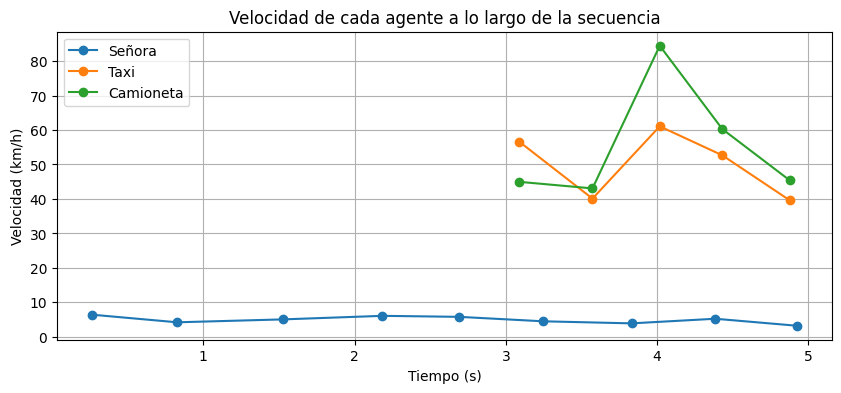

,Agente,Capturas,Δt (s),Distancia (m),Velocidad (m/s),Velocidad (km/h)
0,Señora,0 → 5,0.531,0.95,1.78,6.4
1,Señora,5 → 10,0.593,0.69,1.17,4.2
2,Señora,10 → 15,0.811,1.14,1.40,5.1
3,Señora,15 → 20,0.499,0.84,1.69,6.1
4,Señora,20 → 25,0.515,0.83,1.61,5.8
5,Señora,25 → 30,0.593,0.74,1.25,4.5
6,Señora,30 → 35,0.577,0.62,1.08,3.9
7,Señora,35 → 40,0.530,0.77,1.45,5.2
8,Señora,40 → 45,0.546,0.49,0.89,3.2
9,Taxi,24 → 28,0.468,7.36,15.72,56.6


,Agente,Tiempo total (s),Distancia total (m),Velocidad media (m/s),Velocidad media (km/h)
0,Señora,5.195,6.97,1.34,4.8
1,Taxi,2.247,30.90,13.75,49.5
2,Camioneta,2.247,33.99,15.13,54.5


In [61]:
def calcular_velocidades(t, pos):
    n = len(t)
    vel = np.zeros(n - 1)
    t_medio = np.zeros(n - 1)
    for k in range(n - 1):
        desplazamiento = pos[k + 1, :] - pos[k, :]
        distancia = alc.norma(desplazamiento, 2)
        vel[k] = distancia / (t[k + 1] - t[k])
        t_medio[k] = (t[k] + t[k + 1]) / 2
    return t_medio, vel

def velocidad_media_total(t, pos):
    distancia = alc.norma(pos[-1, :] - pos[0, :], 2)
    return distancia / (t[-1] - t[0])

agentes = [('Señora', marcas_senora, t_senora, pos_senora),
           ('Taxi', marcas_taxi, t_taxi, pos_taxi),
           ('Camioneta', marcas_camioneta, t_camioneta, pos_camioneta)]

filas_intervalos = []
filas_resumen = []

plt.figure(figsize=(10, 4))
for nombre, marcas, t, pos in agentes:
    t_medio, vel = calcular_velocidades(t, pos)
    plt.plot(t_medio, vel * 3.6, marker='o', label=nombre)

    # Una fila por intervalo
    for k in range(len(vel)):
        filas_intervalos.append({
            'Agente': nombre,
            'Capturas': f'{marcas[k][0]} → {marcas[k + 1][0]}',
            'Δt (s)': round(t[k + 1] - t[k], 3),
            'Distancia (m)': round(alc.norma(pos[k + 1, :] - pos[k, :], 2), 2),
            'Velocidad (m/s)': round(vel[k], 2),
            'Velocidad (km/h)': round(vel[k] * 3.6, 1),
        })

    # Una fila de resumen por agente
    v_media = velocidad_media_total(t, pos)
    filas_resumen.append({
        'Agente': nombre,
        'Tiempo total (s)': round(t[-1] - t[0], 3),
        'Distancia total (m)': round(alc.norma(pos[-1, :] - pos[0, :], 2), 2),
        'Velocidad media (m/s)': round(v_media, 2),
        'Velocidad media (km/h)': round(v_media * 3.6, 1),
    })

plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad (km/h)')
plt.title('Velocidad de cada agente a lo largo de la secuencia')
plt.legend()
plt.grid(True)
plt.show()

tabla_intervalos = pd.DataFrame(filas_intervalos)
tabla_resumen = pd.DataFrame(filas_resumen)

display(tabla_intervalos)
display(tabla_resumen)

**Conclusiones**

Las velocidades medias obtenidas son de aproximadamente 4,8 km/h para la señora, 50 km/h para el taxi y 55 km/h para la camioneta. Son valores razonables para una persona caminando y para autos circulando por una calle de la ciudad.

Las velocidades por intervalo presentan oscilaciones, especialmente en los autos. Esto se debe a que el marcado manual tiene un error de algunos píxeles, y ese error se traduce en una incertidumbre en metros que crece con la distancia a la cámara: para puntos a 30-40 m, un píxel equivale a varios decímetros sobre el piso. Al dividir por intervalos de tiempo cortos (menos de medio segundo), estas incertidumbres generan saltos en la velocidad. La velocidad media sobre toda la secuencia es más robusta, porque el desplazamiento total es mucho mayor que el error de marcado.

Además, la conversión a metros depende de la calibración del 5b. Como K se estimó con un modelo simplificado (sesgo nulo, píxeles cuadrados y centro de la imagen en el medio), los resultados pueden tener un error sistemático adicional.

### Ejercicio 6 - Aterrizaje suave
a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)